# Mini-Project 4 — Rainfall Pattern & Crop Suitability Analyser

Compare rainfall regimes in Kampala, Gulu and Mbarara (illustrative monthly mm) and advise farmers on which months
suit which crops. Classes `Region` and `CropRule` live in `src/rainfall.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)
from scipy.spatial.distance import cosine as scipy_cosine_distance
from src.rainfall import (MONTHS, Region, CropRule, DEFAULT_CROPS, cosine_similarity, pearson, euclidean,
                          pairwise_matrix, suitability_table)

## 1. Regions

In [2]:
RAW = {
    "Kampala": [120, 140, 180, 200, 220, 180,  90,  70,  60, 100, 110, 130],
    "Gulu":    [  8,  25,  75, 160, 190, 145, 170, 215, 175, 150,  60,  15],
    "Mbarara": [ 70,  85, 120, 140,  90,  25,  20,  55, 100, 125, 120,  90],
}
regions = [Region(n, v) for n, v in RAW.items()]
summary = pd.DataFrame([{"region": r.name, "annual (mm)": r.annual_total(), "monthly mean (mm)": r.mean(),
                         "wettest": r.wettest_month(), "driest": r.driest_month(), "CV": r.cv()}
                        for r in regions]).set_index("region")
summary

,annual (mm),monthly mean (mm),wettest,driest,CV
region,,,,,
Kampala,"1,600.000",133.333,May,Sep,0.388
Gulu,"1,388.000",115.667,Aug,Jan,0.642
Mbarara,"1,040.000",86.667,Apr,Jul,0.444


## 2. Crop rules

Monthly bands during the growing season, derived from FAO seasonal water requirements (FAO *Crop Water
Information*, Land & Water Division; Brouwer & Heibloem, FAO Irrigation Water Management Training Manual 3, 1986)
spread over the main growing months, plus UCDA guidance for coffee:

| crop | suitable mm/month | basis |
|---|---|---|
| maize | 100–200 | 500–800 mm per ~4-month season |
| beans | 60–150 | 300–500 mm per ~3-month season; poor tolerance of waterlogging |
| coffee | 100–220 | 1,200–2,000 mm/yr, well distributed; needs a short dry spell to flower |

Below the band → *Drought risk*; above → *Waterlogging risk*. These are simplifications: real suitability also
depends on soil, temperature and the crop's growth stage.

In [3]:
crops = DEFAULT_CROPS
for c in crops:
    print(f"{c.crop:>7}: {c.min_mm:.0f}–{c.max_mm:.0f} mm  ({c.source})")
table = suitability_table(regions, crops)
for r in regions:
    df = pd.DataFrame(table[r.name], index=MONTHS).T
    df.loc["rain (mm)"] = r.rainfall.astype(int)
    print(f"\n{r.name}")
    display(df)

  maize: 100–200 mm  (FAO: 500–800 mm per 4-month season → ≈125–200 mm/month)
  beans: 60–150 mm  (FAO: 300–500 mm per ~3-month season; sensitive to waterlogging)
 coffee: 100–220 mm  (FAO/UCDA: arabica/robusta ≈1,200–2,000 mm/yr, well distributed)

Kampala


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
maize,Good for maize,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize
beans,Good for beans,Good for beans,Waterlogging risk,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for beans,Good for beans,Good for beans,Good for beans,Good for beans,Good for beans
coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Drought risk,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee
rain (mm),120,140,180,200,220,180,90,70,60,100,110,130



Gulu


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
maize,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Good for maize,Drought risk,Drought risk
beans,Drought risk,Drought risk,Good for beans,Waterlogging risk,Waterlogging risk,Good for beans,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for beans,Good for beans,Drought risk
coffee,Drought risk,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Drought risk,Drought risk
rain (mm),8,25,75,160,190,145,170,215,175,150,60,15



Mbarara


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
maize,Drought risk,Drought risk,Good for maize,Good for maize,Drought risk,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize,Drought risk
beans,Good for beans,Good for beans,Good for beans,Good for beans,Good for beans,Drought risk,Drought risk,Drought risk,Good for beans,Good for beans,Good for beans,Good for beans
coffee,Drought risk,Drought risk,Good for coffee,Good for coffee,Drought risk,Drought risk,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee,Drought risk
rain (mm),70,85,120,140,90,25,20,55,100,125,120,90


## 3. Fixing last year's cosine similarity

`math.cos(x)` returns the cosine of an **angle** x in radians — feeding it rainfall numbers is meaningless.
Cosine *similarity* is the cosine of the angle *between two vectors*:
$\cos\theta = \dfrac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$. SciPy's `distance.cosine` returns the
cosine **distance** 1 − cos θ, so we compare against 1 − that.

In [4]:
import math
k, m = regions[0].rainfall, regions[2].rainfall
mine = cosine_similarity(k, m)
scipy_val = 1 - scipy_cosine_distance(k, m)
print(f"Kampala–Mbarara  NumPy: {mine:.6f}   SciPy: {scipy_val:.6f}   equal: {np.isclose(mine, scipy_val)}")
print(f"What the old method did, e.g. math.cos(120) = {math.cos(120):.4f}  ← cosine of 120 radians, unrelated to similarity")

Kampala–Mbarara  NumPy: 0.891250   SciPy: 0.891250   equal: True
What the old method did, e.g. math.cos(120) = 0.8142  ← cosine of 120 radians, unrelated to similarity


## 4. Similarity / distance matrices

In [5]:
names = [r.name for r in regions]
mats = {"Cosine similarity": pairwise_matrix(regions, cosine_similarity),
        "Pearson correlation": pairwise_matrix(regions, pearson),
        "Euclidean distance (mm)": pairwise_matrix(regions, euclidean)}
for title, M in mats.items():
    print(title); display(pd.DataFrame(M, index=names, columns=names).round(3))

# Scale demo: a region with exactly 2× Kampala's rain in every month
wet = Region("Kampala×2", regions[0].rainfall * 2)
print(f"Kampala vs Kampala×2 → cosine {cosine_similarity(regions[0].rainfall, wet.rainfall):.3f}, "
      f"Pearson {pearson(regions[0].rainfall, wet.rainfall):.3f}, Euclidean {euclidean(regions[0].rainfall, wet.rainfall):.0f} mm")

Cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


Kampala vs Kampala×2 → cosine 1.000, Pearson 1.000, Euclidean 493 mm


**Why cosine can call a dry and a wet region "similar".** Cosine similarity depends only on the *direction* of the
12-month vector — the shape of the seasonal pattern — not its length. Doubling every month leaves the angle
unchanged, so Kampala and a hypothetical "Kampala × 2" score a perfect 1.0, despite one receiving 1,600 mm more
rain. And because rainfall is never negative, all vectors sit in the positive orthant, so cosine values are
squeezed into a high band (≈ 0.75–0.95 here) and differences look small. Pearson correlation centres each series
first, so it measures the timing of wet and dry months and spreads values over −1…1: Kampala and Gulu have a
cosine of 0.79 but a Pearson correlation of ≈ −0.07 (no shared timing — Gulu's wettest months, Jul–Sep, are
Kampala's driest). Pearson is *also* blind to scale (Kampala × 2 → 1.0). Euclidean distance is the only one of the
three that sees total amount. For crop advice both shape *and* amount matter, so cosine alone
is a poor choice.

## 5. Detecting rainy seasons with `find_peaks`

In [6]:
KNOWN = {"Kampala": "bimodal (MAM & SON — Lake Victoria basin)",
         "Gulu": "unimodal (Apr–Oct, northern Uganda) — with a June dip",
         "Mbarara": "bimodal (MAM & SON — south-western highlands)"}
rows = []
for r in regions:
    for prom in (20, 40):
        rows.append({"region": r.name, "prominence (mm)": prom, "peaks": ", ".join(r.rainy_seasons(prom)),
                     "detected": r.regime(prom), "known climatology": KNOWN[r.name]})
pd.DataFrame(rows)

,region,prominence (mm),peaks,detected,known climatology
0,Kampala,20,May,unimodal,bimodal (MAM & SON — Lake Victoria basin)
1,Kampala,40,May,unimodal,bimodal (MAM & SON — Lake Victoria basin)
2,Gulu,20,"May, Aug",bimodal,"unimodal (Apr–Oct, northern Uganda) — with a J..."
3,Gulu,40,"May, Aug",bimodal,"unimodal (Apr–Oct, northern Uganda) — with a J..."
4,Mbarara,20,"Apr, Oct",bimodal,bimodal (MAM & SON — south-western highlands)
5,Mbarara,40,"Apr, Oct",bimodal,bimodal (MAM & SON — south-western highlands)


The year is treated as **circular** (December wraps to January) so an end-of-year peak is not lost at the array
edge; `prominence` (mm the peak must stand above its surroundings) filters out noise.

* **Mbarara** is clearly bimodal at either threshold — matches the known climate.
* **Gulu** has a June dip, so with a low threshold (20 mm) it shows two peaks; at 40 mm it still shows two (May
  and Aug, 45 mm prominence). Climatologically, northern Uganda is described as a single long Apr–Oct season with a
  *mid-season* dip — so the algorithm detects the dip correctly, but the label "bimodal" overstates it.
* **Kampala** comes out **unimodal** in this illustrative data: the Oct–Dec rise (60 → 130 mm) only reaches 10 mm
  above January, so it does not register as a separate peak. Real Kampala climatology is clearly bimodal (Mar–May and
  Sep–Nov). The mismatch is a property of the illustrative numbers (a weak second season), and shows that peak
  detection is sensitive to the prominence threshold. A more robust rule would combine peak count with season length
  or total rain per season.

## 6. Visualisation

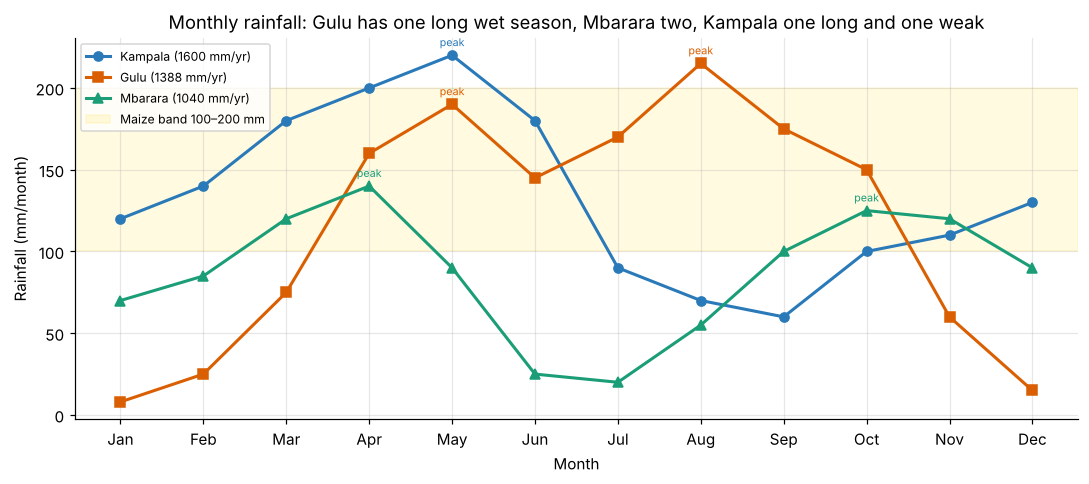

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
styles = {"Kampala": ("#2a7ab9", "o"), "Gulu": ("#d95f02", "s"), "Mbarara": ("#1b9e77", "^")}
for r in regions:
    c, mk = styles[r.name]
    ax.plot(MONTHS, r.rainfall, marker=mk, color=c, lw=2, label=f"{r.name} ({r.annual_total():.0f} mm/yr)")
    for p in r.rainy_seasons(20):
        i = MONTHS.index(p); ax.annotate("peak", (i, r.rainfall[i]), textcoords="offset points", xytext=(0, 6),
                                         ha="center", fontsize=7, color=c)
ax.axhspan(100, 200, color="gold", alpha=0.12, label="Maize band 100–200 mm")
ax.set_ylabel("Rainfall (mm/month)"); ax.set_xlabel("Month")
ax.set_title("Monthly rainfall: Gulu has one long wet season, Mbarara two, Kampala one long and one weak")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "p4_rainfall_lines.png", bbox_inches="tight"); plt.show()

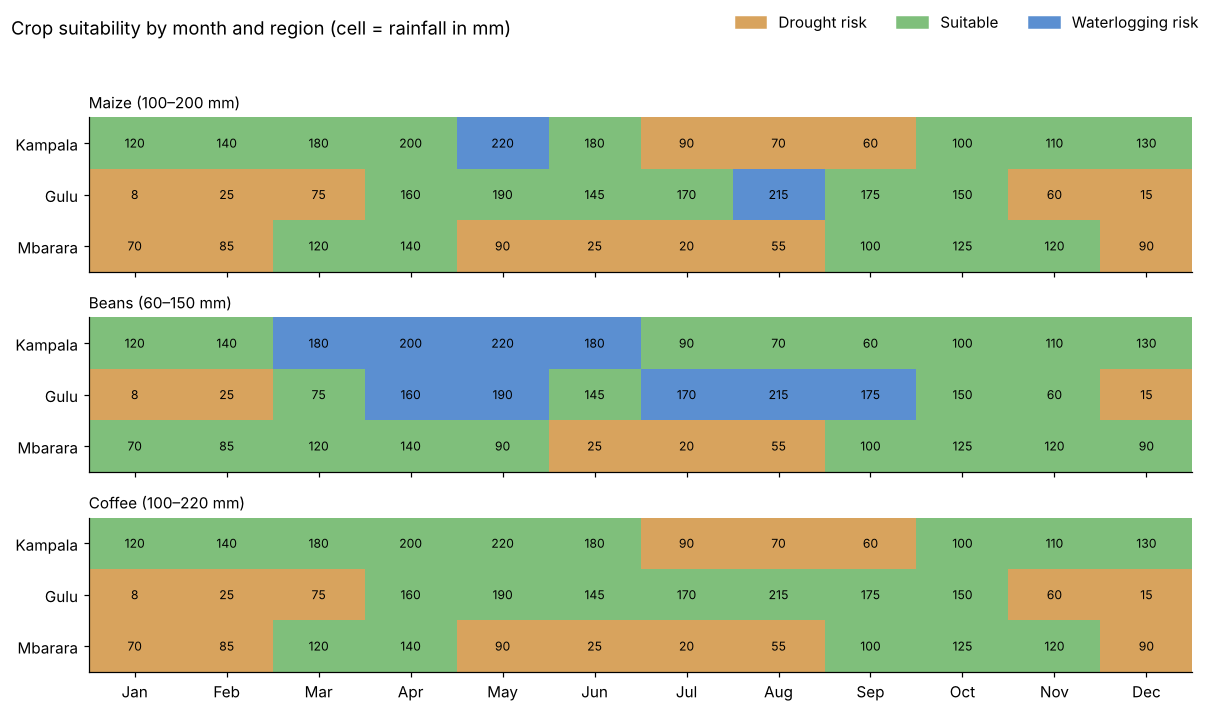

In [8]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#d8a35d", "#7fbf7b", "#5b8fd1"])   # dry / good / wet
fig, axes = plt.subplots(len(crops), 1, figsize=(11, 6.5), sharex=True)
for ax, crop in zip(axes, crops):
    grid = np.array([[crop.score(v) for v in r.rainfall] for r in regions])
    ax.imshow(grid, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for i, r in enumerate(regions):
        for j, v in enumerate(r.rainfall):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8)
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{crop.crop.capitalize()} ({crop.min_mm:.0f}–{crop.max_mm:.0f} mm)", loc="left", fontsize=10)
    ax.grid(False)
axes[-1].set_xticks(range(12), MONTHS)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#d8a35d", label="Drought risk"), Patch(color="#7fbf7b", label="Suitable"),
                    Patch(color="#5b8fd1", label="Waterlogging risk")], loc="upper right", ncol=3, frameon=False)
fig.suptitle("Crop suitability by month and region (cell = rainfall in mm)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / "p4_suitability_heatmap.png", bbox_inches="tight"); plt.show()

In [9]:
# count of suitable months per crop and region, used in the advisory note
pd.DataFrame({c.crop: [sum(c.score(v) == 0 for v in r.rainfall) for r in regions] for c in crops},
             index=[r.name for r in regions]).rename_axis("suitable months")

,maize,beans,coffee
suitable months,,,
Kampala,8,8,9
Gulu,6,4,7
Mbarara,5,9,5


## 7. Advisory note — farmers in Gulu

**Plant maize at the onset of rains in late March to early April.** Rainfall rises from 75 mm in March to
160–190 mm in April–May, inside the maize band, and stays suitable (145–175 mm) through to October except for a
waterlogging-risk spike in August (215 mm). A March–April planting lets the crop establish on April–May rains and
reach harvest by July, before the August peak — dry grain is easier to store and loses less to mould.

**Beans fit best as a second crop.** They are short (about 3 months) and dislike waterlogging, and September
(175 mm) is too wet for them. Plant beans in **late September to early October**, so they grow on October's
150 mm and the tapering November rains (60 mm), and harvest dry in December. Use well-drained, raised beds.

**Avoid planting December to February**: 8–25 mm a month is a clear drought risk for all three crops; use this
period for land preparation and post-harvest handling. Coffee is marginal in Gulu because of this four-month dry
spell; it would need mulching or irrigation.

*Based on illustrative rainfall data; confirm onset dates with UNMA seasonal forecasts each year.* (≈ 190 words)

## Findings & Limitations

**Findings.** Annual totals range from 1,040 mm (Mbarara) to 1,600 mm (Kampala), but the timing of the rain, more
than the total, decides what farmers can grow. Mbarara is clearly bimodal (peaks in April
and October) with a harsh June–August dry spell (20–55 mm); Gulu has one long wet season from April to October and
a dry spell from December to February (8–25 mm); Kampala is wettest overall and has the longest suitable window,
with 8–9 suitable months for each crop. Beans suit Mbarara best (9 months) because its moderate rains rarely exceed
the waterlogging limit, while maize only has 5 suitable months there.

The similarity analysis shows why metric choice matters. Cosine similarity rated all pairs as fairly "similar"
(0.75–0.89) because non-negative rainfall vectors always point in roughly the same direction; Pearson correlation
showed the patterns are in fact almost unrelated in timing (−0.17 to 0.21). Both are blind to scale, so only
Euclidean distance reflects how much more rain one place gets. Peak detection matched known climatology for
Mbarara, flagged Gulu's mid-season dip as a second "season", and missed Kampala's weak second season in this
illustrative data; the result depends on the prominence threshold.

**Limitations.** Monthly averages hide the main risk farmers face: year-to-year variation in onset and
dry spells inside a month. Crop bands are simplified from seasonal totals and ignore soil, temperature,
evapotranspiration and growth stage (e.g. coffee needs a dry spell to flower, which a "drought risk" label hides).
The data are illustrative; using 10+ years of real NASA POWER/UNMA data would allow probabilistic advice
("in 8 of 10 years April exceeds 100 mm"). The extension with real data was not attempted because it requires
data download.